In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import datetime
import glob
import joblib
import shutil
import umap

sys.path.insert(0, "cellular_cycle") # add path to the model

from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files
SET_JPARAM = False # Set the parameter values for the simulation using PSO-optimized values

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

GENERATE_UMAP = False

/home/darren/miniconda/envs/ECM_model/lib/python3.10/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/darren/miniconda/envs/ECM_model/lib/python3.10/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/darren/miniconda/envs/ECM_model/lib/python3.10/site-packag

### Detect computer system
UMAP embeddings are dependent on processor, OS and package versions

In [2]:
sys_type = sys.platform
print(sys_type)

linux


### Show versions of relevant packages

In [3]:
umap_version = umap.__version__
print(umap_version)

0.5.3


### Load Data

Expecting these files if using original parameters:  
```
[PosixPath('/Users/darren/ECM_mod_output/stoch_sim_soft_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_soft_erl_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_int_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_int_erl_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_stiff_erl_param_cycdi_0_0.csv')]
 ```

In [4]:
if SET_JPARAM:
    filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_psoparam_cycdi_0_0' in f]
else:
    filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_param_cycdi_0_0' in f]
filenames = sorted(filenames)

filenames_conds = [filenames[2], filenames[3], filenames[0],
                filenames[1], filenames[4], filenames[5]]

filenames_conds


[PosixPath('/home/darren/ECM_mod_output/stoch_sim_soft_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/stoch_sim_soft_erl_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/stoch_sim_int_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/stoch_sim_int_erl_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/stoch_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/stoch_sim_stiff_erl_param_cycdi_0_0.csv')]

In [5]:
if SET_JPARAM:
    filenames_ode = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'ODE_sim' in f and '_psoparam_cycdi_0_0' in f]
else:
    filenames_ode = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'ODE_sim' in f and  '_param_cycdi_0_0' in f]
    
filenames_ode = sorted(filenames_ode)

filenames_conds_ode = [filenames_ode[2], filenames_ode[3], filenames_ode[0],
                filenames_ode[1], filenames_ode[4], filenames_ode[5]]

filenames_conds_ode


[PosixPath('/home/darren/ECM_mod_output/ODE_sim_soft_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/ODE_sim_soft_erl_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/ODE_sim_int_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/ODE_sim_int_erl_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/ODE_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/home/darren/ECM_mod_output/ODE_sim_stiff_erl_param_cycdi_0_0.csv')]

### Set UMAP parameters

In [6]:
# Important params to set the window size and step time distance
init_dt = 0.1                 # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

# set the random state for reproducibility; set to None to get different results each time
RANDOM_STATE = 42



### Define UMAP reducer filename

In [7]:
#reducer save name
if SET_JPARAM:
    r_name = f'reducer_psoparams_{CURDATE}_{init_dt}_{dt}_{window}_{time_step}.sav'
else:
    r_name = f'reducer_{CURDATE}_{init_dt}_{dt}_{window}_{time_step}.sav'

In [8]:
if sys_type == 'darwin':
    r_path_date = '20240502'
    r_dbpath = 'https://www.dropbox.com/scl/fi/ovk8v5fc9rvsbm43zww8h/reducer_20240502_0.1_0.1_4_0.5.sav?rlkey=jb9om518rtjth0q9bs6mdjj79&dl=1'
if sys_type == 'win32': 
    r_path_date = '03_20'
    r_dbpath = 'https://www.dropbox.com/scl/fi/jlfya4m3bhp9akr3hzco2/reducer_03_20_0.1_0.1_4_0.5.sav?rlkey=3z8ozy95khsjdqplkg8ce11md&dl=1'
if sys_type == 'linux': 
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

r_path = Path(SAVE_DIR,'UMAP',r_name.replace(f'{CURDATE}',r_path_date))

%env R_PATH = {r_path}
%env R_DBPATH = {r_dbpath}

env: R_PATH=/home/darren/ECM_mod_output/UMAP/reducer_20240606_0.1_0.1_4_0.5.sav
env: R_DBPATH=https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1


In [9]:
def calc_minmax(filenames, filenames_ode):
    # values to be replaced
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this now
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots

In [10]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_{num}.png"), bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_norm_{num}.png"), bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [11]:
max_prots, min_prots = calc_minmax(filenames_conds, filenames_conds_ode)

In [12]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [13]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_conds, filenames_conds_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [14]:
# quick check of protein time course shape
assert all_prot_tmp.shape == (239958, 720)

In [15]:
# check global max and min vals
assert [np.amax(all_prot_tmp), np.amin(all_prot_tmp)] == [1.0,0.0]

### Get reducer (model for UMAP embedding)

In [16]:
if GENERATE_UMAP:
    reducer = umap.UMAP(
                        n_neighbors=neighbs,
                        min_dist=min_d,
                        n_components=2,
                        metric='euclidean',
                        random_state=RANDOM_STATE,
                        low_memory=True        
                        ).fit(all_prot_tmp)
else:
    if not r_path.exists():
        !wget -O $R_PATH $R_DBPATH
    reducer = joblib.load(r_path)

### Generate embedding of stochastic trajectories

In [17]:
embedding_all_prot = reducer.transform(all_prot_tmp)

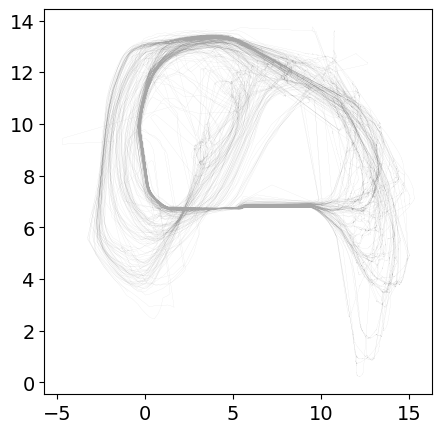

In [18]:
# Check how the UMAP projection looks
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_conds))
trk_len_ode = int(len(embedding_all_prot)/len(filenames_conds))

n=1
n1=2

plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
         lw=0.05, alpha=0.7, c='gray')



In [19]:
# Save the UMAP object
if GENERATE_UMAP:
    reducer_filename = Path(SAVE_DIR, 'UMAP', r_name)
    if not Path(SAVE_DIR,'UMAP').exists():
        os.mkdir(Path(SAVE_DIR,'UMAP'))
    if not reducer_filename.exists() or OVERWRITE:
        joblib.dump(reducer, reducer_filename)

In [20]:
# We don't need the full runs from the ODE solutions for the UMAP, we can use a shortened segment of the run
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames)
sp = 1
for n in range(len(filenames)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [21]:
all_prot_tmp_ode_ab.shape

(12000, 720)

### Generate embedding of ODE solutions

In [22]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [23]:
# Save all the outputs
if SET_JPARAM:
    if  not Path(SAVE_DIR, f'all_embedding_ode_conds_psoparams_{CURDATE}.sav').exists() or OVERWRITE:
        print(f'Saving UMAP outputs for pso parameters {CURDATE}.')
        joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_conds_psoparams_{CURDATE}.sav'))
        joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_conds_psoparams_{CURDATE}.sav'))
        joblib.dump(all_prot_tmp, Path(SAVE_DIR, f'all_prot_stoch_conds_psoparams_{CURDATE}.sav'))
else:
    if  not Path(SAVE_DIR, f'all_embedding_ode_conds_{CURDATE}.sav').exists() or OVERWRITE:
        print(f'Saving UMAP outputs for original parameters {CURDATE}.')
        joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_conds_{CURDATE}.sav'))
        joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_conds_{CURDATE}.sav'))
        joblib.dump(all_prot_tmp, Path(SAVE_DIR, f'all_prot_stoch_conds_{CURDATE}.sav'))
